# 03 · Preparación de los datos: segmentación de la fruta

**Fase 3 de CRISP-DM.** El EDA (notebook 02, sección 4.1) mostró que en Kaggle **el fondo delata la clase**:
un clasificador que solo ve el borde de la imagen logra F1 ≈ 0,89 en *good* y *bad*. Para que los modelos
aprendan de la fruta y no del fondo, se segmenta la fruta en cada imagen.

Este notebook: (1) explica y compara los métodos de segmentación; (2) mide si la segmentación elimina el
atajo del fondo; (3) revisa las fallas; (4) evalúa la máscara como medida de tamaño.

Las máscaras se generan una vez con `python -m src.data.generar_mascaras` y se guardan en `data/masks/`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from src.config import FRUITS, QUALITY_CLASSES, SEED
from src.data.carga import cargar_splits, cargar_imagen
from src.data.segmentacion import mascara_fruta, componente_mayor, segmentar_fruta, aplicar_mascara
from src.data.generar_mascaras import ruta_mascara

FIG_DIR = ROOT / "docs" / "figures"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight", "svg.fonttype": "none"})
COLORES = {"good": "#2a9d8f", "regular": "#e9b949", "bad": "#d1495b"}
FUENTE = {"kaggle": "#6c757d", "own": "#3a86ff"}

df = cargar_splits()   # incluye mask_area y d_eq (make_splits.py los toma de data/masks.csv)
cargar_mascara = lambda f: np.asarray(Image.open(ruta_mascara(f["path"]))) > 0
print(len(df), "imágenes con máscara")

5705 imágenes con máscara


## 1. Método

**Umbral simple** (`mascara_fruta`): un píxel es fruta si su distancia euclídea RGB al color mediano del borde
supera 40:

$$ m(x) = \mathbb{1}\left[\lVert I(x) - \tilde{c}_{\text{borde}} \rVert_2 > 40 \right] $$

Es el criterio que usa `prepare_dataset.py`. Falla cuando el fondo no es uniforme (texturas, sombras, manos).

**GrabCut con priors** (`segmentar_fruta`, el que se adopta). GrabCut [Rother et al., 2004] modela el color de
la fruta y del fondo con dos mezclas de 5 gaussianas, $p(I(x)\mid \alpha)$ con $\alpha \in \{\text{fondo},
\text{fruta}\}$, y busca la etiqueta $\alpha$ que minimiza la energía

$$ E(\alpha) = \sum_x -\log p\big(I(x)\mid \alpha_x\big) \;+\; \gamma \sum_{(x,y)\ \text{vecinos}}
[\alpha_x \neq \alpha_y]\, e^{-\beta \lVert I(x)-I(y)\rVert^2} $$

El primer término pide que cada píxel se parezca al modelo de color de su clase; el segundo penaliza cortar
entre píxeles vecinos de color parecido, así que el borde de la máscara sigue los bordes de la imagen. La
energía se minimiza exactamente con un corte mínimo en un grafo y se alterna con la reestimación de las
gaussianas (5 iteraciones). En vez del rectángulo clásico, se inicializa con conocimiento del problema:
fondo seguro = borde con color de fondo; fruta probable = píxeles distintos del fondo cerca del centro;
fruta segura = núcleo central saturado. Al final se conserva el componente conexo más grande.

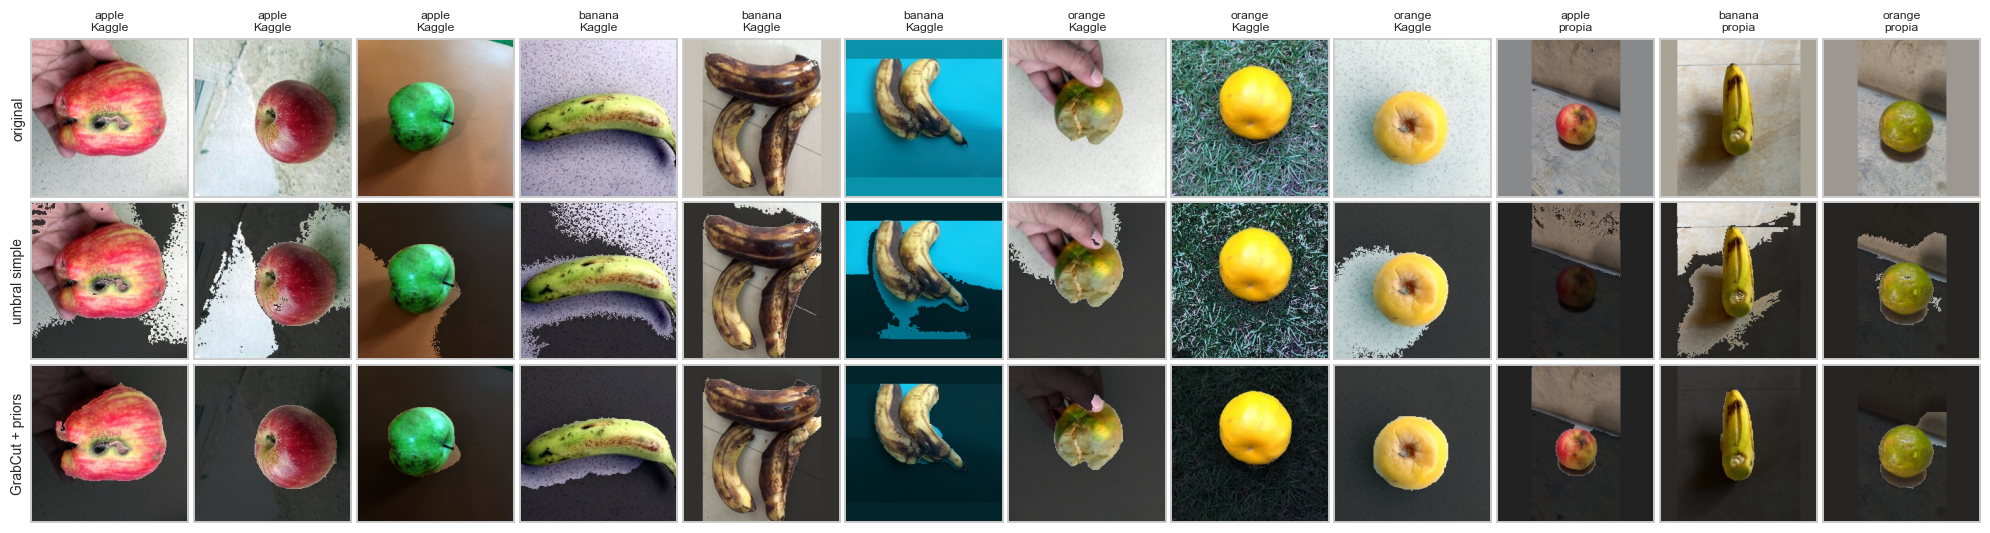

In [2]:
rng = np.random.default_rng(SEED)
muestra = pd.concat([df[df.source == "kaggle"].groupby("fruit").sample(3, random_state=SEED),
                     df[df.source == "own"].groupby("fruit").sample(1, random_state=SEED)])

def oscurecer(rgb, m):
    o = rgb.copy(); o[~m] = (o[~m] * 0.25).astype(np.uint8); return o

fig, axes = plt.subplots(3, len(muestra), figsize=(1.5 * len(muestra), 4.8))
for c, (_, f) in enumerate(muestra.iterrows()):
    rgb = np.asarray(cargar_imagen(f))
    for r, img in enumerate([rgb, oscurecer(rgb, componente_mayor(mascara_fruta(rgb))),
                             oscurecer(rgb, cargar_mascara(f))]):
        axes[r, c].imshow(img); axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
    axes[0, c].set_title(f"{f.fruit}\n{'propia' if f.source == 'own' else 'Kaggle'}", fontsize=8)
for r, t in enumerate(["original", "umbral simple", "GrabCut + priors"]):
    axes[r, 0].set_ylabel(t, fontsize=9)
fig.tight_layout(pad=0.3)
fig.savefig(FIG_DIR / "prep_segmentacion_ejemplos.png", dpi=150)
plt.show()

## 2. ¿La segmentación elimina el atajo del fondo?

Se entrena el mismo Random Forest del EDA (validación cruzada por grupos, 5 folds, solo `train`) con tres
conjuntos de características de color (mediana, desviación y percentiles 10/90 en RGB y HSV):

- **A · solo fondo**: píxeles **fuera** de la máscara → cuánto predice el fondo (el atajo).
- **B · solo fruta**: píxeles **dentro** de la máscara → la señal legítima que debe aprender el modelo.
- **C · borde de la imagen enmascarada**: franja del 8 % del borde después de pintar el fondo de gris → cuánto
  fondo (o mano) se cuela dentro de la máscara.

Si la segmentación funciona, **C** debe quedar cerca del azar y **B** debe conservar buena parte del rendimiento.

In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import f1_score

def stats_color(rgb_pix):
    if len(rgb_pix) < 10:
        return [0.0] * 24
    hsv = np.asarray(Image.fromarray(rgb_pix.reshape(-1, 1, 3).astype(np.uint8)).convert("HSV"),
                     np.float32).reshape(-1, 3)
    out = []
    for p in (rgb_pix.astype(np.float32) / 255, hsv / 255):
        out += list(np.median(p, 0)) + list(p.std(0)) + list(np.percentile(p, 10, 0)) + list(np.percentile(p, 90, 0))
    return out

def franja_borde(a, frac=0.08):
    b = max(2, int(frac * a.shape[0]))
    return np.concatenate([a[:b].reshape(-1, 3), a[-b:].reshape(-1, 3), a[:, :b].reshape(-1, 3), a[:, -b:].reshape(-1, 3)])

tr = df[df.split == "train"].reset_index(drop=True)
XA, XB, XC = [], [], []
for _, f in tr.iterrows():
    rgb, m = np.asarray(cargar_imagen(f)), cargar_mascara(f)
    XA.append(stats_color(rgb[~m])); XB.append(stats_color(rgb[m]))
    XC.append(stats_color(franja_borde(aplicar_mascara(rgb, m))))

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1)
res = []
for nombre, X in [("A · solo fondo", XA), ("B · solo fruta", XB), ("C · borde enmascarado", XC)]:
    pred = cross_val_predict(rf, np.array(X), tr.y, groups=tr.grupo, cv=cv)
    f1c = f1_score(tr.y, pred, average=None)
    res.append({"características": nombre, "macro-F1": f1_score(tr.y, pred, average="macro"),
                **{f"F1 {c}": v for c, v in zip(QUALITY_CLASSES, f1c)}})
azar = f1_score(tr.y, np.random.default_rng(SEED).permutation(tr.y.values), average="macro")
res = pd.DataFrame(res).set_index("características").round(3)
print(f"Referencia (etiquetas barajadas): macro-F1 = {azar:.3f}")
res

Referencia (etiquetas barajadas): macro-F1 = 0.331


,macro-F1,F1 good,F1 regular,F1 bad
características,,,,
A · solo fondo,0.599,0.884,0.025,0.887
B · solo fruta,0.620,0.903,0.051,0.906
C · borde enmascarado,0.255,0.370,0.075,0.319


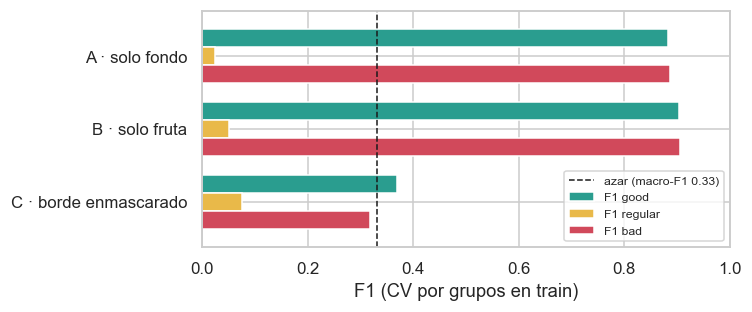

In [4]:
fig, ax = plt.subplots(figsize=(7, 3))
res[[f"F1 {c}" for c in QUALITY_CLASSES]].plot.barh(ax=ax, color=[COLORES[c] for c in QUALITY_CLASSES], width=0.75)
ax.axvline(azar, ls="--", c="k", lw=1, label=f"azar (macro-F1 {azar:.2f})")
ax.invert_yaxis(); ax.set(xlabel="F1 (CV por grupos en train)", ylabel="", xlim=(0, 1))
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "prep_atajo_fondo.svg")
plt.show()

## 3. Calidad de las máscaras y fallas

Sin máscaras dibujadas a mano no se puede calcular IoU; se usan indicadores indirectos: fracción de la imagen
cubierta por la máscara y casos extremos (máscara diminuta = probablemente perdió la fruta; máscara enorme =
probablemente incluyó fondo o mano).

estado         normal
source fruit         
kaggle apple     2004
       banana    1619
       orange    2036
own    apple       17
       banana      15
       orange      14

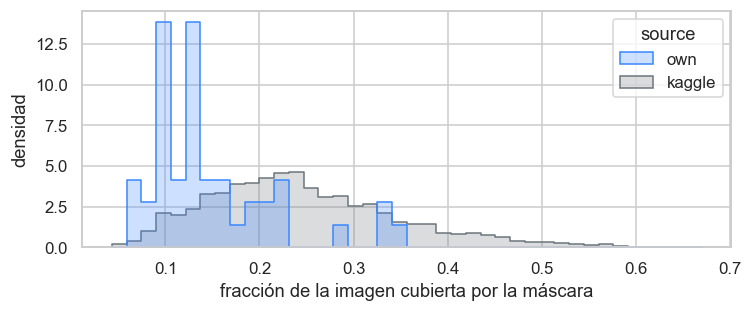

In [5]:
df["estado"] = np.select([df.mask_area < 0.03, df.mask_area > 0.85], ["muy pequeña (<3 %)", "muy grande (>85 %)"], "normal")
display(pd.crosstab([df.source, df.fruit], df.estado))

fig, ax = plt.subplots(figsize=(7, 3))
sns.histplot(data=df, x="mask_area", hue="source", palette=FUENTE, stat="density", common_norm=False,
             bins=40, element="step", ax=ax)
ax.set(xlabel="fracción de la imagen cubierta por la máscara", ylabel="densidad")
fig.tight_layout(); fig.savefig(FIG_DIR / "prep_area_mascara.svg"); plt.show()

In [6]:
extremos = pd.concat([df[df.estado == "muy pequeña (<3 %)"].sample(min(4, (df.estado == "muy pequeña (<3 %)").sum()), random_state=SEED),
                      df[df.estado == "muy grande (>85 %)"].sample(min(4, (df.estado == "muy grande (>85 %)").sum()), random_state=SEED)])
if len(extremos):
    fig, axes = plt.subplots(1, len(extremos), figsize=(1.6 * len(extremos), 2))
    for ax, (_, f) in zip(np.atleast_1d(axes), extremos.iterrows()):
        ax.imshow(oscurecer(np.asarray(cargar_imagen(f)), cargar_mascara(f)))
        ax.set_title(f"{f.fruit} {f.mask_area:.2f}", fontsize=8); ax.axis("off")
    plt.show()

## 4. La máscara como medida de tamaño

El enunciado pide el tamaño (pequeño/mediano/grande) o el diámetro en píxeles normalizados. Con la máscara se
puede calcular un **diámetro equivalente normalizado**, el diámetro del círculo de igual área dividido entre el
lado de la imagen:

$$ d_{eq} = \frac{2}{L}\sqrt{\frac{A_{\text{máscara}}}{\pi}} = 2\sqrt{\frac{\texttt{mask\_area}}{\pi}} $$

`tamano` en `splits.csv` son los terciles de `d_eq` por fruta, con cortes calculados en `train`. Como
`area_ratio`, sigue siendo un tamaño **relativo a la foto**: solo es comparable entre fotos tomadas a una
distancia parecida.

Spearman d_eq vs area_ratio (original): {'kaggle': 0.437, 'own': 0.086}


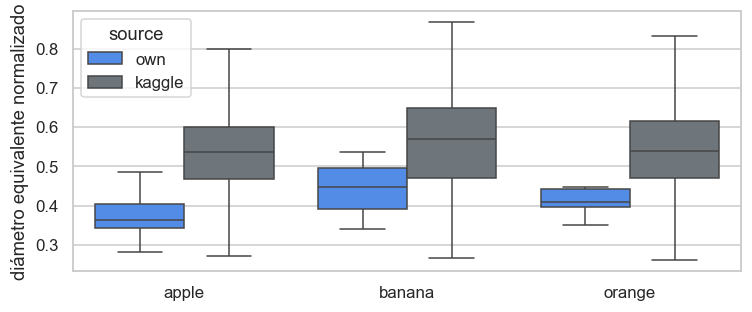

Clase de tamaño (terciles de d_eq por fruta, cortes con train):


tamano,pequeno,mediano,grande
source,,,
kaggle,1897,1889,1873
own,38,4,4


In [7]:
print("Spearman d_eq vs area_ratio (original):",
      df.groupby("source")[["d_eq", "area_ratio"]].corr(method="spearman").xs("area_ratio", level=1)["d_eq"].round(3).to_dict())
fig, ax = plt.subplots(figsize=(7, 3))
sns.boxplot(data=df, x="fruit", y="d_eq", hue="source", palette=FUENTE, order=FRUITS, showfliers=False, ax=ax)
ax.set(xlabel="", ylabel="diámetro equivalente normalizado")
fig.tight_layout(); fig.savefig(FIG_DIR / "prep_diametro_equivalente.svg"); plt.show()

print("Clase de tamaño (terciles de d_eq por fruta, cortes con train):")
pd.crosstab(df.source, df.tamano).reindex(columns=["pequeno", "mediano", "grande"])

## 5. Conclusiones

1. **GrabCut con priors segmenta mucho mejor que el umbral simple.** El umbral simple incluye texturas de
   fondo, sombras y superficies; GrabCut aísla la fruta en la gran mayoría de los casos (~200 ms por imagen).
   Ninguna máscara quedó en los extremos (< 3 % o > 85 % de la imagen). Falla conocida: en Kaggle la mano que
   sostiene la fruta puede quedar parcialmente dentro de la máscara (excluir piel por color no sirve porque se
   solapa con el color de las frutas).
2. **La segmentación elimina el atajo del fondo.** Con solo el fondo (A) se logra F1 ≈ 0,88 en *good* y *bad*;
   con el borde de la imagen ya enmascarada (C) el rendimiento cae por debajo del azar (macro-F1 0,26 frente a
   0,33): no queda información útil del fondo dentro de la máscara.
3. **La fruta sola conserva toda la señal.** Con color de la fruta (B) se logra F1 ≈ 0,90 en *good* y *bad*, un
   poco más que con el fondo. Esto justifica entrenar sobre la fruta segmentada: se pierde el atajo sin perder
   rendimiento, y el modelo debería generalizar mejor a fondos nuevos (`test_propias`).
4. **"regular" no se detecta con estadísticas de color globales** (F1 ≤ 0,08 en A, B y C). Hará falta
   información local (textura, manchas, bordes) o una CNN, además de compensar el desbalance.
5. **El tamaño se mide con la máscara.** `area_ratio` (umbral simple sobre la foto original) es poco fiable: en
   las fotos propias, con piso texturizado, vale ~0,6 cuando la fruta ocupa ~10 % de la imagen (Spearman con la
   máscara: 0,09). Se adopta el **diámetro equivalente normalizado** `d_eq = 2·sqrt(mask_area/π)`, que el
   enunciado admite ("diámetro en píxeles normalizados"); `tamano` en `splits.csv` son ahora los terciles de
   `d_eq` por fruta (cortes con train). El tamaño es una medida geométrica, no algo que aprenda un modelo.
6. **El tamaño en píxeles depende de la distancia de captura.** 38 de las 46 fotos propias quedan como
   "pequeño" porque se tomaron más lejos que las de Kaggle, no porque las frutas sean pequeñas. Para que la
   clase de tamaño tenga sentido en el despliegue hay que **fijar la distancia de la cámara** (o usar un objeto
   de referencia) y calibrar los cortes en ese montaje.